In [21]:
from langgraph.graph import StateGraph, MessagesState, START, END
from typing import TypedDict

## DEFINE STATE


In [22]:
class TemperatureState(TypedDict):
    temp_celsius :  float
    temp_fahrenheit: float
    weather_status: str

# Convert Temperature Function (First Node)

In [23]:
def convert_temp(state: TemperatureState) -> TemperatureState:
    celsius = state['temp_celsius']
    fahrenheit = (celsius * 9/5) + 32

    state['temp_fahrenheit'] = round(fahrenheit, 2)
    
    return state

# Label Weather Condition 2nd Node


In [24]:
def label_weather (state : TemperatureState) -> TemperatureState:

    # Pull Fahrenheit from the state instead of Celcius
    fahrenheit = state['temp_fahrenheit']

    if fahrenheit < 50:
        state['weather_status'] = 'Cold'
    elif 50 <= fahrenheit < 77:
        state['weather_status'] = 'Mild'
    elif 77 <= fahrenheit < 95:
        state['weather_status'] = 'Hot'
        
    return state

# Define and Compile Graph

In [25]:
# Define Your Graph
graph = StateGraph(TemperatureState)

# add nodes to your graph 
graph.add_node('convert_temp', convert_temp)
graph.add_node('label_weather_status', label_weather)

# add edges to the graph
graph.add_edge(START, 'convert_temp')
graph.add_edge('convert_temp', 'label_weather_status')
graph.add_edge('label_weather_status', END)

# Compile the graph
workflow = graph.compile()

# Execute Graph

In [26]:
initial_state = { 'temp_celsius' : 28.5 }
final_state = workflow.invoke(initial_state)
print(final_state)

{'temp_celsius': 28.5, 'temp_fahrenheit': 83.3, 'weather_status': 'Hot'}


# Visualise Graph

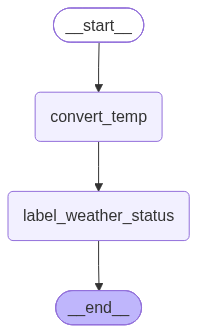

In [27]:
from IPython.display import Image
Image(workflow.get_graph().draw_mermaid_png())